# Couverture réactive — étude complète

Ce notebook regroupe toutes les méthodes et les compare sur les trois instances (`data12`, `data4`, `data2`) :

| Étape du sujet | Méthode |
|---|---|
| 1 | métriques d'évaluation d'une solution (fonction `evaluer`, indépendante des solveurs) |
| 2 | passages complets : **glouton** et **MILP** |
| 3 | passages partiels : **glouton + réduction des fenêtres** et **MILP** |
| 4 | bi-critère coût / satisfaction : **front de Pareto** par contrainte de budget |

Chaque résolution est limitée à 2 minutes comme demandé dans le sujet.

In [1]:
import json
import math
import matplotlib.pyplot as plt


def plotSolution(data,solution):

    # Charger le GeoJSON
    with open("countries.geo.json") as f:
        dataCountries = json.load(f)

    # get some data
    minVisiDuration = data['minVisiDuration']
    AOIs = data['AOIs']
    accesses = data['Accesses']
    satPasses = data['Passes']
    
    # get the booking strategy
    bookings = solution['Bookings']
    bookings.sort(key=lambda item: satPasses[item["passId"]]['startDate'])    
    print("Bookings:")
    for booking in bookings:
        print(booking)
    
    # show the passes used
    ncols = 3
    nrows = math.ceil(len(solution['Bookings']) / ncols)
    fig, axs = plt.subplots(nrows=nrows,ncols=ncols, figsize=(30,30))
    axs = axs.flatten()

    i = 0
    for booking in solution['Bookings']:
        passId = booking["passId"]
        satPass = satPasses[passId]
        ax = axs[i]
        
        # Dessiner les frontières
        for feature in dataCountries["features"]:
            geometry = feature["geometry"]
    
            if geometry["type"] == "Polygon":
                for coords in geometry["coordinates"]:
                    xs, ys = zip(*coords)
                    ax.fill(xs, ys, facecolor="lightgray", edgecolor="black", linewidth=0.5)

            elif geometry["type"] == "MultiPolygon":
                for polygon in geometry["coordinates"]:
                    for coords in polygon:
                        xs, ys = zip(*coords)
                        ax.fill(xs, ys, facecolor="lightgray", edgecolor="black", linewidth=0.5)

        
        ax.set_xlim(-9, 13)
        ax.set_ylim(38, 56)
        ax.set_title("Pass #{} [{},{}]".format(passId,satPass['startDate'],satPass['endDate']))
        ax.plot([aoi['lon'] for aoi in AOIs], [aoi['lat'] for aoi in AOIs], 'kx')

        # show the reservations
        xpoints = []
        ypoints = []
        colors = []
        for accessId in satPass['accessIds']:
            access = accesses[accessId]
            aoi = AOIs[access['aoiId']]
            xpoints.append(aoi['lon'])
            ypoints.append(aoi['lat'])
            if (booking['bookingStart'] <= access['end'] - minVisiDuration) and (access['start'] + minVisiDuration <= booking['bookingEnd']):
                colors.append('r')
            else:
                colors.append('b')       
        ax.scatter(xpoints,ypoints,marker='o',c=colors)
        
        i = i + 1


plt.show()



## 1. Métriques et outils communs

Une solution est évaluée **uniquement à partir des réservations exportées** (`bookingStart`, `bookingEnd`) :
- **coût** = Σ (`fixedPassCost` + `passCostPerTimeUnit` × durée réservée) ;
- **requêtes satisfaites par priorité** : une requête est satisfaite si l'un de ses accès est recouvert
  pendant au moins `minVisiDuration` = 30 s par une réservation ;
- **score** = satisfaction pondérée (poids 100 / 10 / 1 pour les priorités 1 / 2 / 3), utilisé à l'étape 4.

Cette fonction sert aussi de vérificateur : elle recalcule tout sans faire confiance au solveur.

In [2]:
import json
import time
import pandas as pd
import gurobipy as gp
from gurobipy import GRB

INSTANCES = ['data12', 'data4', 'data2']
TIME_LIMIT = 120          # temps max autorisé par le sujet (2 minutes)
POIDS = {1: 100, 2: 10, 3: 1}   # poids des priorités pour le critère "satisfaction"


def charger(nom):
    with open(f'../data/{nom}.json') as f:
        return json.load(f)


def cout_reservation(data, debut, fin):
    return data['fixedPassCost'] + data['passCostPerTimeUnit'] * (fin - debut)


def evaluer(data, bookings):
    """Vérificateur indépendant des solveurs : recalcule le coût et les requêtes
    satisfaites à partir des seules réservations (bookingStart / bookingEnd)."""
    D = data['minVisiDuration']
    acces = data['Accesses']
    fenetre = {b['passId']: (b['bookingStart'], b['bookingEnd']) for b in bookings}
    couvert = [False] * len(acces)
    for a, acc in enumerate(acces):
        if acc['passId'] in fenetre:
            s, e = fenetre[acc['passId']]
            couvert[a] = min(e, acc['end']) - max(s, acc['start']) >= D
    res = {'nb passages': len(bookings),
           'coût': sum(cout_reservation(data, b['bookingStart'], b['bookingEnd']) for b in bookings)}
    score = 0
    for prio in (1, 2, 3):
        reqs = [r for r in data['ObservationRequests'] if r['priority'] == prio]
        if reqs:
            ok = sum(any(couvert[a] for a in r['accessIds']) for r in reqs)
            res[f'prio {prio}'] = f'{ok}/{len(reqs)}'
            score += POIDS[prio] * ok
    res['score'] = score
    return res


def score_max(data):
    return sum(POIDS[r['priority']] for r in data['ObservationRequests'])


def bookings_depuis(data, fenetres):
    """fenetres : {passId: (debut, fin)} -> liste de réservations au format JSON du sujet."""
    passes = data['Passes']
    return [{'passId': p, 'passStart': passes[p]['start'], 'passEnd': passes[p]['end'],
             'bookingStart': int(round(s)), 'bookingEnd': int(round(e))}
            for p, (s, e) in sorted(fenetres.items())]


def exporter(bookings, fichier='mySolution.json'):
    with open(fichier, 'w') as f:
        json.dump({'Bookings': bookings}, f)

## 2–3. Modèles MILP (Gurobi)

**Variables** : `x_p` = passage p réservé ; en partiel, `debut_p`, `fin_p` = fenêtre réservée et `z_a` = accès a couvert.

**Passages complets** : une requête r est satisfaite si au moins un passage contenant un de ses accès est réservé
→ `Σ x_p ≥ 1` (problème de couverture d'ensemble, résolu instantanément).

**Passages partiels** : l'accès a (dans le passage p) est couvert si le chevauchement entre `[debut_p, fin_p]` et
`[start_a, end_a]` dure au moins D. Avec `z_a = 1` cela s'écrit :
- `debut_p ≤ end_a − D` (on commence assez tôt) ;
- `fin_p ≥ start_a + D` (on finit assez tard) ;
- `fin_p − debut_p ≥ D` (la fenêtre elle-même dure au moins D).

Ces contraintes sont désactivées par big-M quand `z_a = 0`. Les big-M sont calculés au plus juste pour chaque accès
(ex. `M = end_p − end_a + D`) pour renforcer la relaxation linéaire.

**Deux modes** :
- `budget=None` : minimiser le coût en satisfaisant toutes les requêtes ;
- `budget=B` : maximiser la satisfaction pondérée sous `coût ≤ B` (méthode ε-contrainte, étape 4).

Le MILP peut démarrer depuis la solution du glouton (`depart`).

In [3]:
def resoudre_milp(data, partiel, budget=None, time_limit=TIME_LIMIT, depart=None, verbose=False):
    """MILP Gurobi.
    - budget=None : minimise le coût en satisfaisant toutes les requêtes.
    - budget=B    : maximise la satisfaction pondérée sous la contrainte coût <= B
                    (petite pénalité sur le coût pour départager les ex-aequo).
    partiel=False : on réserve des passages complets ; True : une fenêtre [debut, fin] par passage.
    depart : réservations servant de solution initiale (optionnel)."""
    passes, acces, requetes = data['Passes'], data['Accesses'], data['ObservationRequests']
    D = data['minVisiDuration']
    nP, nA = len(passes), len(acces)

    m = gp.Model('couverture_reactive')
    m.Params.OutputFlag = 1 if verbose else 0
    m.Params.TimeLimit = time_limit

    x = m.addVars(nP, vtype=GRB.BINARY, name='x')          # passage réservé
    if partiel:
        debut = m.addVars(nP, vtype=GRB.INTEGER, name='debut')
        fin = m.addVars(nP, vtype=GRB.INTEGER, name='fin')
        z = m.addVars(nA, vtype=GRB.BINARY, name='z')      # accès couvert
        for i, p in enumerate(passes):
            debut[i].LB = fin[i].LB = p['start']
            debut[i].UB = fin[i].UB = p['end']
            m.addConstr(debut[i] <= fin[i])
            m.addConstr(fin[i] - debut[i] <= (p['end'] - p['start']) * x[i])
            m.addConstr(fin[i] - debut[i] >= D * x[i])    # renforcement : une fenêtre < D ne sert à rien
        for a, acc in enumerate(acces):
            i = acc['passId']
            p = passes[i]
            if acc['end'] - acc['start'] < D:
                z[a].UB = 0
                continue
            # accès couvert <=> chevauchement [debut,fin] ∩ [acc.start,acc.end] >= D
            # big-M calculés au plus juste pour chaque accès (relaxation linéaire plus forte)
            m.addConstr(z[a] <= x[i])
            m.addConstr(debut[i] <= acc['end'] - D + (p['end'] - acc['end'] + D) * (1 - z[a]))
            m.addConstr(fin[i] >= acc['start'] + D - (acc['start'] + D - p['start']) * (1 - z[a]))
            m.addConstr(fin[i] - debut[i] >= D * z[a])
        couvre = lambda a: z[a]
        cout = gp.quicksum(data['fixedPassCost'] * x[i] + data['passCostPerTimeUnit'] * (fin[i] - debut[i])
                           for i in range(nP))
    else:
        couvre = lambda a: x[acces[a]['passId']] if acces[a]['end'] - acces[a]['start'] >= D else 0
        cout = gp.quicksum(cout_reservation(data, p['start'], p['end']) * x[i] for i, p in enumerate(passes))

    if budget is None:
        for r in requetes:
            m.addConstr(gp.quicksum(couvre(a) for a in r['accessIds']) >= 1)
        m.setObjective(cout, GRB.MINIMIZE)
    else:
        y = m.addVars(len(requetes), vtype=GRB.BINARY, name='y')   # requête satisfaite
        for k, r in enumerate(requetes):
            m.addConstr(y[k] <= gp.quicksum(couvre(a) for a in r['accessIds']))
        m.addConstr(cout <= budget)
        satisfaction = gp.quicksum(POIDS[r['priority']] * y[k] for k, r in enumerate(requetes))
        m.setObjective(satisfaction - 1e-4 * cout, GRB.MAXIMIZE)

    if partiel and budget is None:
        m.Params.MIPFocus = 3     # la difficulté est de prouver l'optimalité : on travaille la borne
        m.Params.Cuts = 2
    if depart is not None:        # solution initiale (ex. glouton) pour démarrer la recherche
        fen = {b['passId']: (b['bookingStart'], b['bookingEnd']) for b in depart}
        for i in range(nP):
            x[i].Start = 1 if i in fen else 0
            if partiel and i in fen:
                debut[i].Start, fin[i].Start = fen[i]

    t0 = time.time()
    m.optimize()
    duree = time.time() - t0
    if m.SolCount == 0:
        return None, {'temps (s)': round(duree, 1), 'statut': 'pas de solution'}

    fenetres = {}
    for i, p in enumerate(passes):
        if x[i].X > 0.5:
            fenetres[i] = (debut[i].X, fin[i].X) if partiel else (p['start'], p['end'])
    infos = {'temps (s)': round(duree, 1),
             'statut': 'optimal' if m.Status == GRB.OPTIMAL else 'limite de temps',
             'gap (%)': round(100 * m.MIPGap, 2)}
    return bookings_depuis(data, fenetres), infos

## 2–3. Heuristique gloutonne

1. **Construction** : on ajoute le passage complet qui maximise *(poids des requêtes nouvellement satisfaites) / coût*,
   jusqu'à ce que toutes les requêtes soient satisfaites.
2. **Nettoyage** : on retire les passages devenus inutiles (les plus chers d'abord).
3. **Réduction (partiels)** : pour chaque passage, on calcule la plus petite fenêtre qui satisfait encore les requêtes
   dont il est le seul responsable. On teste chaque début candidat (début d'accès ou fin d'accès − D) et on prend
   la plus petite fin compatible.

Très rapide (< 1 s) : sert de référence et de solution de départ pour le MILP.

In [4]:
def glouton(data, partiel):
    """Heuristique gloutonne + améliorations :
    1. ajoute à chaque étape le passage complet avec le meilleur rapport
       (poids des nouvelles requêtes satisfaites) / coût, jusqu'à tout couvrir ;
    2. retire les passages devenus redondants (les plus chers d'abord) ;
    3. si partiel : réduit chaque passage à la plus petite fenêtre qui garde
       satisfaites les requêtes dont il est le seul à s'occuper."""
    t0 = time.time()
    passes, acces, requetes = data['Passes'], data['Accesses'], data['ObservationRequests']
    D = data['minVisiDuration']
    nP = len(passes)

    # requêtes satisfaites par chaque passage complet
    req_par_passage = [set() for _ in range(nP)]
    for k, r in enumerate(requetes):
        for a in r['accessIds']:
            if acces[a]['end'] - acces[a]['start'] >= D:
                req_par_passage[acces[a]['passId']].add(k)
    cout_complet = [cout_reservation(data, p['start'], p['end']) for p in passes]

    # 1. construction gloutonne
    a_couvrir = set(range(len(requetes)))
    choisis = []
    while a_couvrir:
        def ratio(i):
            return sum(POIDS[requetes[k]['priority']] for k in req_par_passage[i] & a_couvrir) / cout_complet[i]
        meilleur = max((i for i in range(nP) if i not in choisis), key=ratio)
        if ratio(meilleur) == 0:
            break          # plus rien de couvrable
        choisis.append(meilleur)
        a_couvrir -= req_par_passage[meilleur]

    # 2. suppression des passages redondants
    for i in sorted(choisis, key=lambda i: -cout_complet[i]):
        autres = set().union(*(req_par_passage[j] for j in choisis if j != i))
        if req_par_passage[i] <= autres:
            choisis.remove(i)

    fenetres = {i: (passes[i]['start'], passes[i]['end']) for i in choisis}

    # 3. réduction des fenêtres (passages partiels)
    if partiel:
        def couverts(i, s, e):
            return {a for a in passes[i]['accessIds']
                    if min(e, acces[a]['end']) - max(s, acces[a]['start']) >= D}

        for i in sorted(choisis, key=lambda i: -cout_complet[i]):
            # requêtes satisfaites par les autres passages (avec leurs fenêtres actuelles)
            acc_autres = set().union(*(couverts(j, *fenetres[j]) for j in fenetres if j != i))
            besoins = []    # pour chaque requête qui dépend de i : ses accès dans le passage i
            for k in req_par_passage[i]:
                r = requetes[k]
                if not any(a in acc_autres for a in r['accessIds']):
                    besoins.append([a for a in r['accessIds']
                                    if acces[a]['passId'] == i and acces[a]['end'] - acces[a]['start'] >= D])
            if not besoins:
                del fenetres[i]
                continue
            # on teste chaque début candidat et on calcule la plus petite fin compatible
            debuts = sorted({acces[a]['start'] for b in besoins for a in b} |
                            {acces[a]['end'] - D for b in besoins for a in b})
            meilleure = fenetres[i]
            for s in debuts:
                e = s + D
                for b in besoins:
                    fins = [max(s, acces[a]['start']) + D for a in b if acces[a]['end'] - max(s, acces[a]['start']) >= D]
                    if not fins:
                        e = None
                        break
                    e = max(e, min(fins))
                if e is not None and e - s < meilleure[1] - meilleure[0]:
                    meilleure = (s, e)
            fenetres[i] = meilleure

    infos = {'temps (s)': round(time.time() - t0, 1), 'statut': 'heuristique', 'gap (%)': None}
    return bookings_depuis(data, fenetres), infos

## 4. Comparaison des méthodes sur les trois instances

`solution fournie` = fichiers `solutionXX.json` donnés avec le sujet (référence de départ).
⚠️ Cette cellule prend environ 5 minutes (le MILP partiel peut atteindre la limite de 2 min).

In [5]:
resultats = []
solutions = {}
for nom in INSTANCES:
    data = charger(nom)
    with open(f'../data/solution{nom[4:]}.json') as f:
        ref = json.load(f)['Bookings']
    resultats.append({'instance': nom, 'méthode': 'solution fournie', **evaluer(data, ref)})
    for methode, partiel in [('complets', False), ('partiels', True)]:
        b_glouton, infos = glouton(data, partiel)
        solutions[(nom, f'glouton {methode}')] = b_glouton
        resultats.append({'instance': nom, 'méthode': f'glouton {methode}', **evaluer(data, b_glouton), **infos})
        b_milp, infos = resoudre_milp(data, partiel, depart=b_glouton)
        solutions[(nom, f'MILP {methode}')] = b_milp
        resultats.append({'instance': nom, 'méthode': f'MILP {methode}', **evaluer(data, b_milp), **infos})
        print(nom, methode, 'terminé')

tableau = pd.DataFrame(resultats)
tableau

Set parameter Username
Set parameter LicenseID to value 2880831
Academic license - for non-commercial use only - expires 2027-11-03
data12 complets terminé
data12 partiels terminé
data4 complets terminé
data4 partiels terminé
data2 complets terminé
data2 partiels terminé


,instance,méthode,nb passages,coût,prio 1,score,temps (s),statut,gap (%),prio 2,prio 3
0,data12,solution fournie,9,3245.0,225/225,22500,NaN,NaN,NaN,NaN,NaN
1,data12,glouton complets,6,2122.0,225/225,22500,0.0,heuristique,NaN,NaN,NaN
2,data12,MILP complets,4,1525.0,225/225,22500,0.0,optimal,0.00,NaN,NaN
3,data12,glouton partiels,6,1453.0,225/225,22500,0.0,heuristique,NaN,NaN,NaN
4,data12,MILP partiels,4,1078.0,225/225,22500,120.0,limite de temps,13.64,NaN,NaN
5,data4,solution fournie,43,14870.0,225/225,42590,NaN,NaN,NaN,2009/2009,NaN
6,data4,glouton complets,28,10021.0,225/225,42590,0.0,heuristique,NaN,2009/2009,NaN
7,data4,MILP complets,28,9991.0,225/225,42590,0.0,optimal,0.00,2009/2009,NaN
8,data4,glouton partiels,28,6258.0,225/225,42590,0.0,heuristique,NaN,2009/2009,NaN
9,data4,MILP partiels,29,5994.0,225/225,42590,120.0,limite de temps,0.97,2009/2009,NaN


### Écart du glouton par rapport au MILP

In [6]:
# écart du glouton par rapport au MILP (même type de passages)
lignes = []
for nom in INSTANCES:
    for methode in ['complets', 'partiels']:
        c = {r['méthode']: r['coût'] for r in resultats if r['instance'] == nom}
        lignes.append({'instance': nom, 'passages': methode, 'coût MILP': c[f'MILP {methode}'],
                       'coût glouton': c[f'glouton {methode}'],
                       'écart glouton (%)': round(100 * (c[f'glouton {methode}'] / c[f'MILP {methode}'] - 1), 1)})
pd.DataFrame(lignes)

,instance,passages,coût MILP,coût glouton,écart glouton (%)
0,data12,complets,1525.0,2122.0,39.1
1,data12,partiels,1078.0,1453.0,34.8
2,data4,complets,9991.0,10021.0,0.3
3,data4,partiels,5994.0,6258.0,4.4
4,data2,complets,16847.0,17055.0,1.2
5,data2,partiels,10872.0,11372.0,4.6


## 5. Étape 4 : front de Pareto coût / satisfaction

On remplace le critère de coût par une **contrainte de budget** et on maximise la satisfaction pondérée.
On fait varier le budget de 1/8 à 100 % du coût minimal trouvé ci-dessus (20 s max par point).

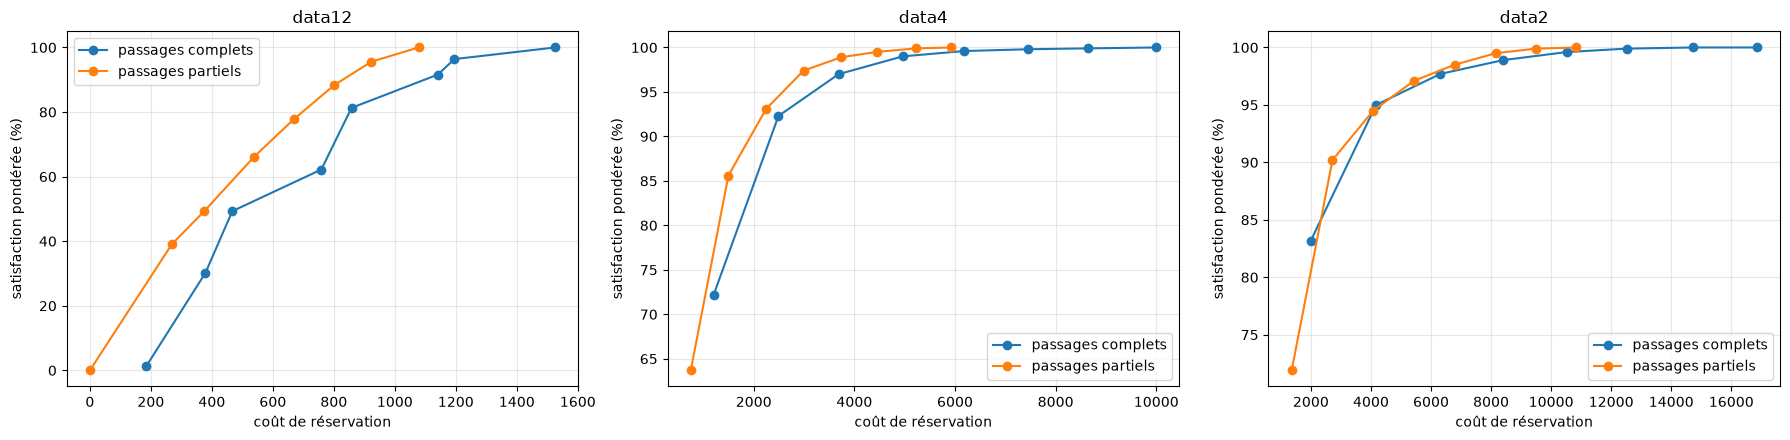

data12 complets
 budget  nb passages   coût  prio 1  score  satisfaction (%)  statut
    191            1  185.0   3/225    300               1.3 optimal
    381            1  379.0  68/225   6800              30.2 optimal
    572            1  467.0 111/225  11100              49.3 optimal
    762            2  759.0 140/225  14000              62.2 optimal
    953            2  858.0 183/225  18300              81.3 optimal
   1144            3 1141.0 206/225  20600              91.6 optimal
   1334            3 1195.0 217/225  21700              96.4 optimal
   1525            4 1525.0 225/225  22500             100.0 optimal
data12 partiels
 budget  nb passages   coût  prio 1  score  satisfaction (%)          statut
    135            0    0.0   0/225      0               0.0         optimal
    270            1  269.0  88/225   8800              39.1         optimal
    404            1  375.0 111/225  11100              49.3 limite de temps
    539            2  539.0 149/225  14

In [7]:
import matplotlib.pyplot as plt

PARETO_TIME_LIMIT = 20     # par point, pour garder un temps total raisonnable
N_POINTS = 8

fig, axes = plt.subplots(1, len(INSTANCES), figsize=(6 * len(INSTANCES), 4.5))
fronts = {}
for ax, nom in zip(axes, INSTANCES):
    data = charger(nom)
    smax = score_max(data)
    for methode, partiel in [('complets', False), ('partiels', True)]:
        cout_max = next(r['coût'] for r in resultats if r['instance'] == nom and r['méthode'] == f'MILP {methode}')
        points = []
        for k in range(1, N_POINTS + 1):
            budget = cout_max * k / N_POINTS
            bookings, infos = resoudre_milp(data, partiel, budget=budget, time_limit=PARETO_TIME_LIMIT)
            if bookings is None:
                continue
            ev = evaluer(data, bookings)
            points.append({'budget': round(budget), **ev, 'satisfaction (%)': round(100 * ev['score'] / smax, 1),
                           'statut': infos['statut']})
        fronts[(nom, methode)] = pd.DataFrame(points)
        ax.plot([p['coût'] for p in points], [p['satisfaction (%)'] for p in points], 'o-', label=f'passages {methode}')
    ax.set_title(nom)
    ax.set_xlabel('coût de réservation')
    ax.set_ylabel('satisfaction pondérée (%)')
    ax.grid(alpha=.3)
    ax.legend()
plt.tight_layout()
plt.show()

for (nom, methode), df in fronts.items():
    print(nom, methode)
    print(df.to_string(index=False))

## 6. Visualisation d'une solution

Accès en rouge = couverts par la réservation, en bleu = non couverts. Changer `instance` / `methode` pour afficher une autre solution.

Bookings:
{'passId': 2, 'passStart': 1104, 'passEnd': 1449, 'bookingStart': 1190, 'bookingEnd': 1220}
{'passId': 13, 'passStart': 8816, 'passEnd': 8943, 'bookingStart': 8903, 'bookingEnd': 8933}
{'passId': 14, 'passStart': 9254, 'passEnd': 9464, 'bookingStart': 9281, 'bookingEnd': 9392}
{'passId': 16, 'passStart': 10949, 'passEnd': 11113, 'bookingStart': 11024, 'bookingEnd': 11077}
{'passId': 17, 'passStart': 11293, 'passEnd': 11607, 'bookingStart': 11340, 'bookingEnd': 11567}
{'passId': 18, 'passStart': 12132, 'passEnd': 12479, 'bookingStart': 12197, 'bookingEnd': 12306}
{'passId': 20, 'passStart': 13829, 'passEnd': 14131, 'bookingStart': 13894, 'bookingEnd': 14059}
{'passId': 21, 'passStart': 14336, 'passEnd': 14448, 'bookingStart': 14399, 'bookingEnd': 14429}
{'passId': 22, 'passStart': 14759, 'passEnd': 14982, 'bookingStart': 14781, 'bookingEnd': 14891}
{'passId': 25, 'passStart': 16809, 'passEnd': 17113, 'bookingStart': 16955, 'bookingEnd': 17087}
{'passId': 26, 'passStart': 17649

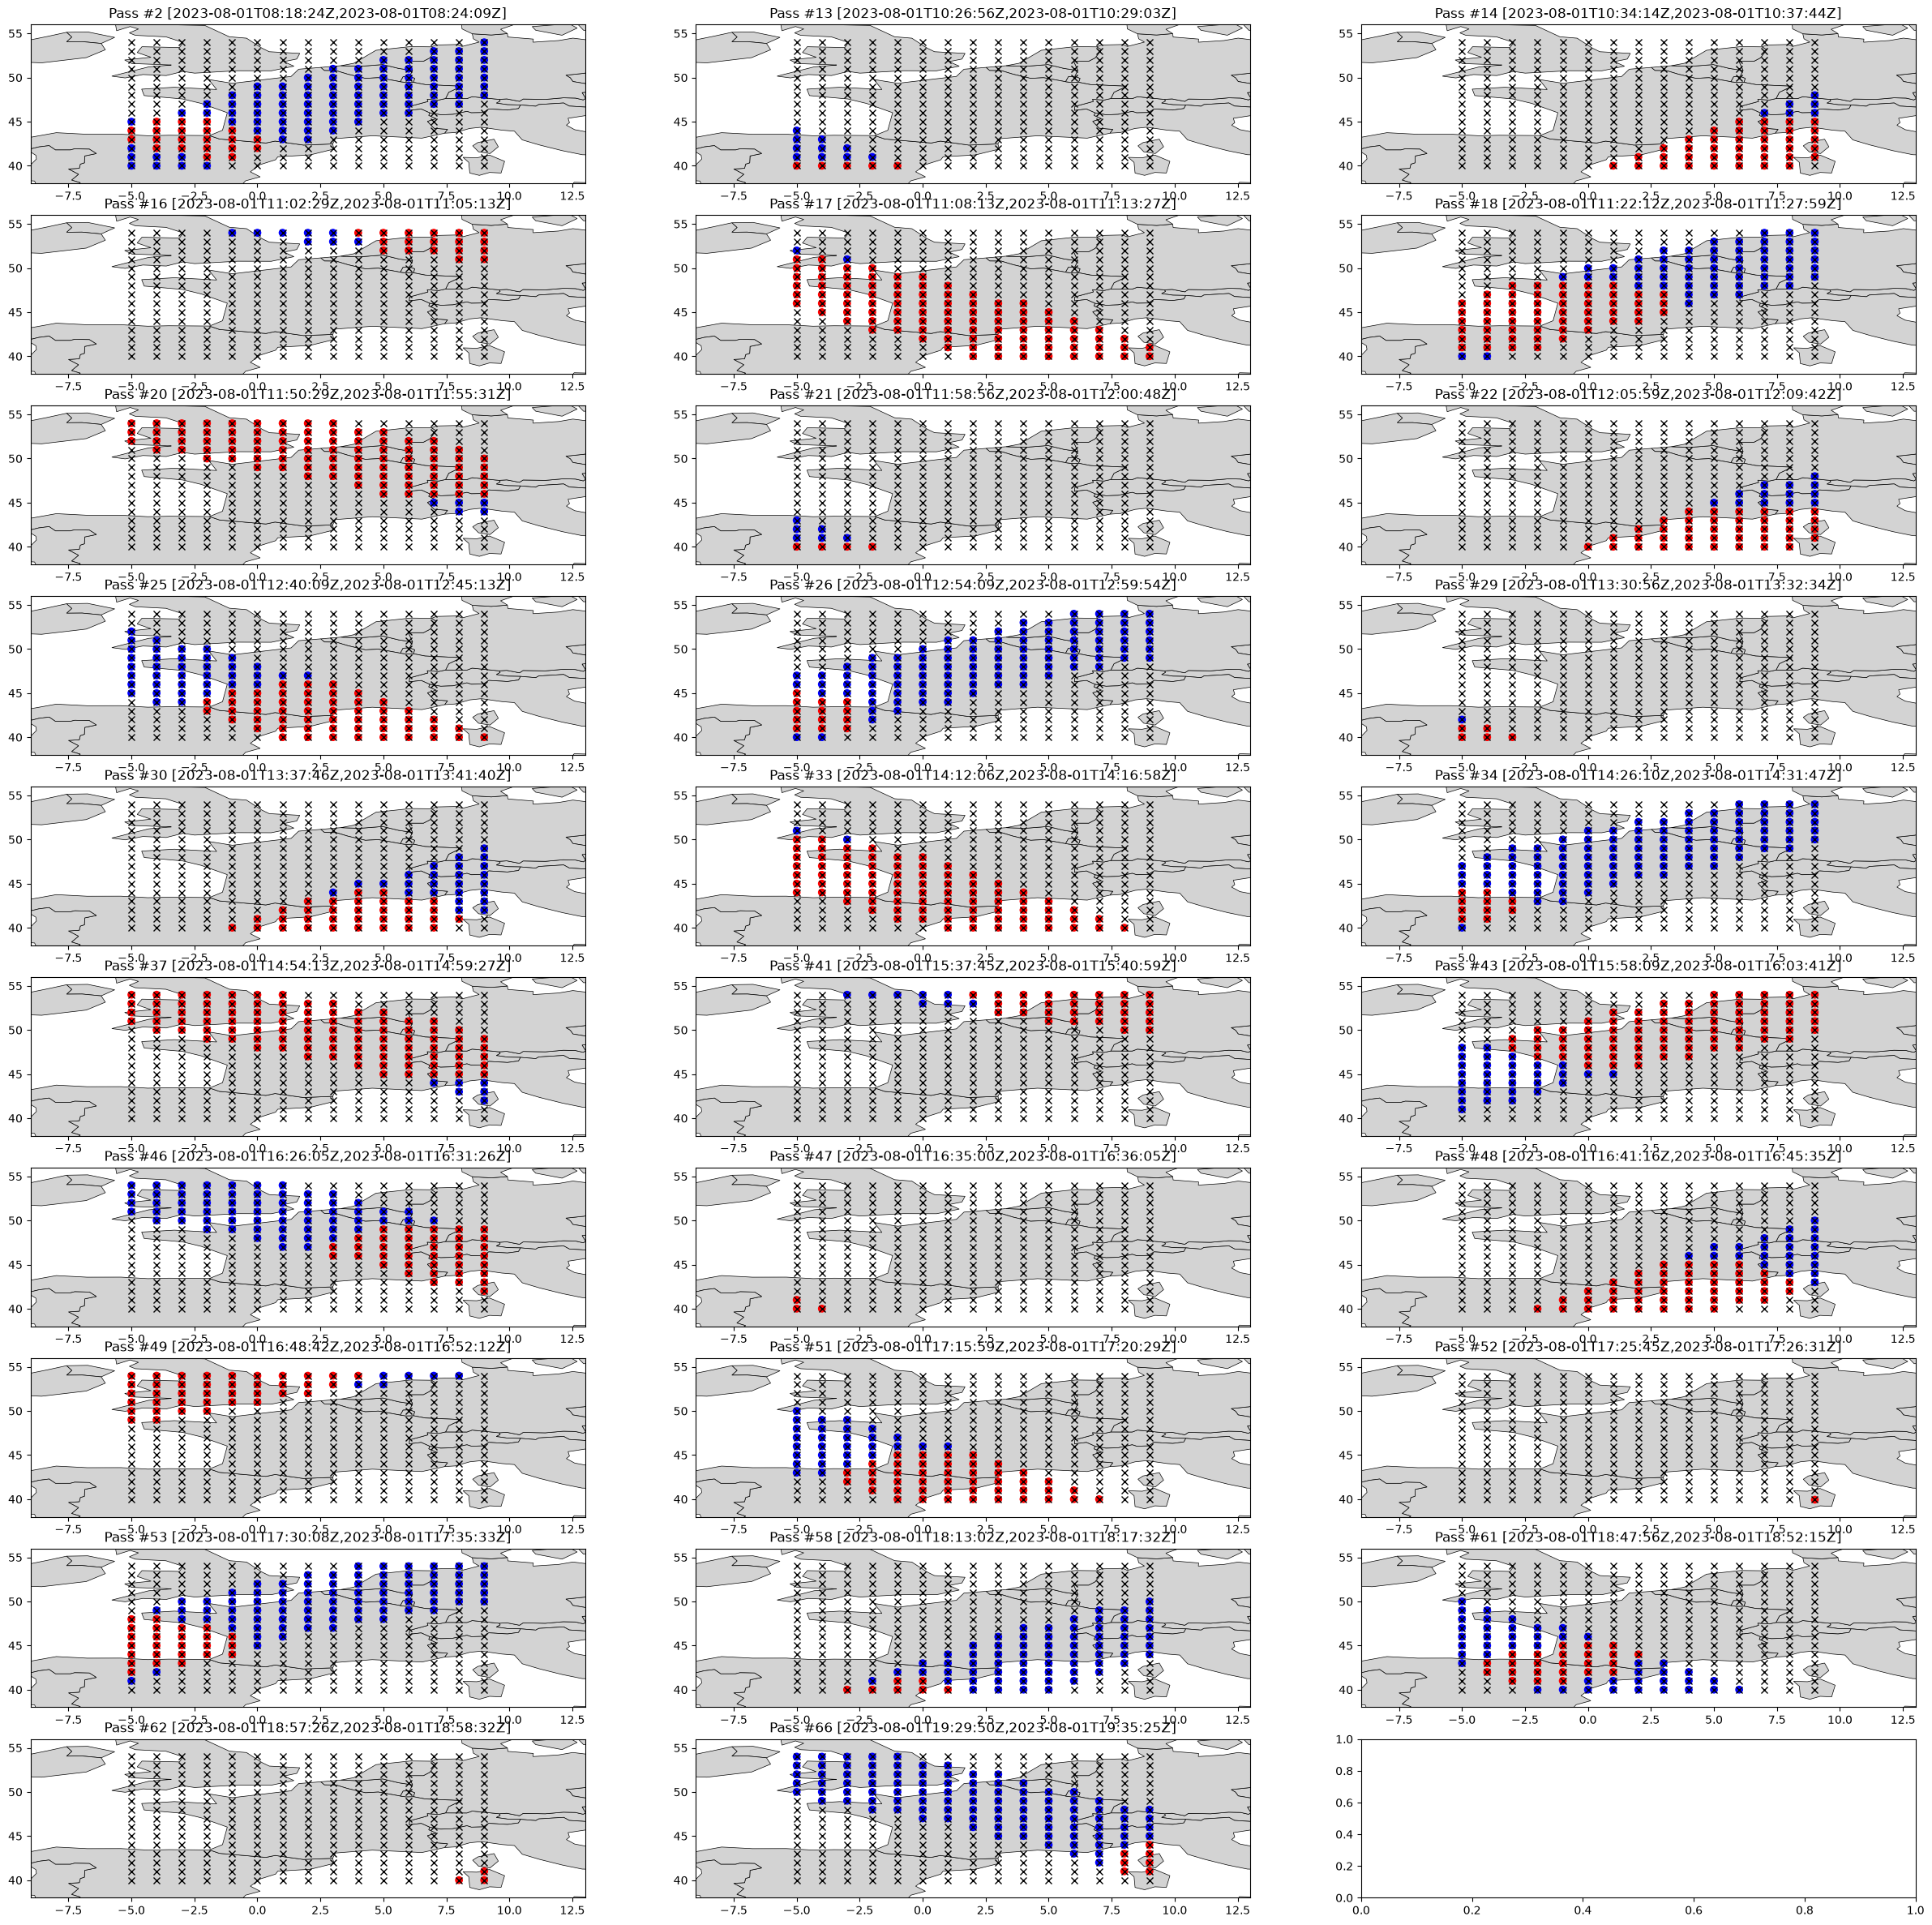

In [8]:
instance, methode = 'data4', 'MILP partiels'
data = charger(instance)
plotSolution(data, {'Bookings': solutions[(instance, methode)]})
exporter(solutions[(instance, methode)])   # écrit aussi mySolution.json

## 7. Analyse (à compléter avec vos observations)

- **Passages partiels vs complets** : réserver uniquement la partie utile d'un passage réduit fortement le coût
  (environ −30 % à −40 % selon l'instance) pour la même satisfaction.
- **Glouton vs MILP** : le glouton est quasi instantané et reste à quelques % de l'optimum sur `data4` / `data2`,
  mais il est plus éloigné sur `data12` (peu de requêtes, choix initiaux plus déterminants).
- **Difficulté du MILP partiel** : le modèle avec passages complets est résolu à l'optimum instantanément.
  Le modèle partiel est plus dur : les big-M affaiblissent la relaxation linéaire et il reste un gap sur `data12`
  au bout de 2 min (borne inférieure mal prouvée, même si la solution trouvée est probablement très bonne).
  Piste : une formulation par fenêtres candidates (choisir une fenêtre parmi un ensemble fini par passage).
- **Pareto** : la courbe montre le coût marginal de la réactivité. Une grande partie de la satisfaction pondérée
  (priorité 1 surtout) est obtenue avec une petite fraction du budget, les derniers % coûtent cher
  (ex. data4 : 97 % de satisfaction pour ~30 % du coût total).
- Le front « partiels » domine le front « complets », sauf ponctuellement (data2 autour d'un coût de 4000) :
  ces points partiels sont arrêtés par la limite de temps, donc pas forcément optimaux.